# **Improve Retrieval algorithm**

![Retrieval Refinement in a RAG Pipeline.png](<attachment:Retrieval Refinement in a RAG Pipeline.png>)


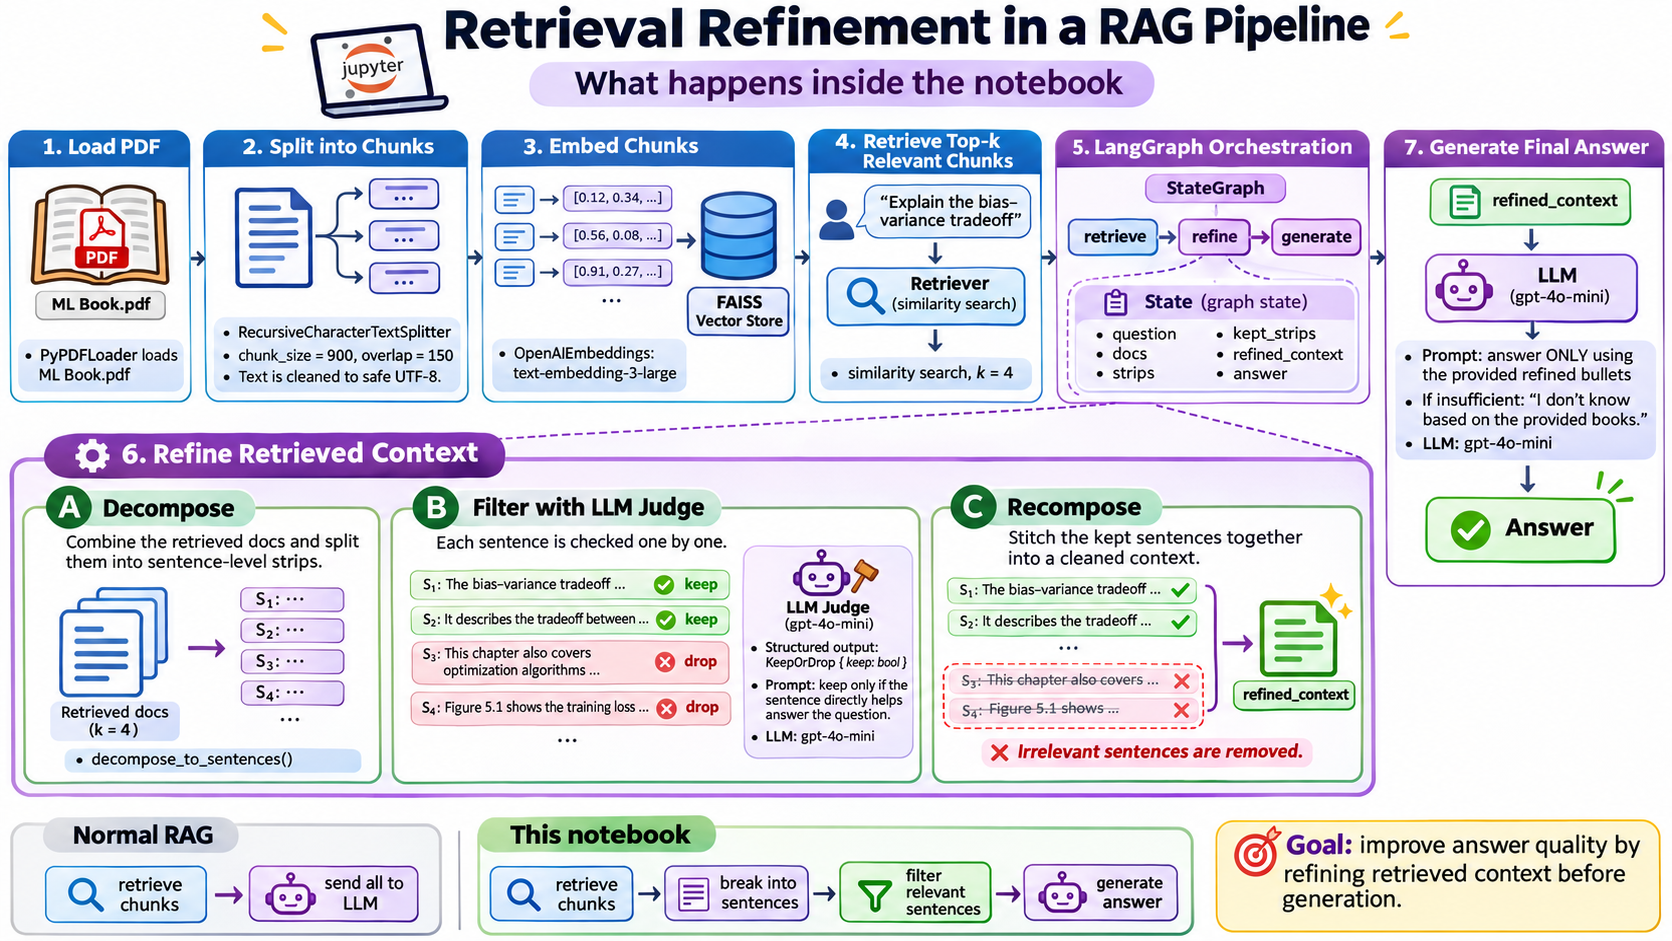

## Retrieval Refinement: Decompose → Filter → Recompose

In this step, we improve the quality of the retrieved context before passing it to the final LLM. Instead of using all retrieved text, we split it into sentences, evaluate their relevance, and keep only the useful information.

### 1. Overall Workflow

```text
User Question
      │
      ▼
FAISS Retriever (Top-k Documents)
      │
      ▼
DECOMPOSE
Split retrieved documents into individual sentences
      │
      ▼
FILTER (LLM Judge)
Evaluate each sentence against the user question
      │
      ├── keep=True  → Keep sentence
      │
      └── keep=False → Discard sentence
      │
      ▼
RECOMPOSE
Combine relevant sentences into refined_context
      │
      ▼
Answer Generation (LLM)
```

### 2. Step-by-Step Explanation

**Step 1: Decomposition**

The retrieved documents are combined into a single text and split into individual sentences using `decompose_to_sentences()`.

```python
context = "\n\n".join(d.page_content for d in state["docs"]).strip()
strips = decompose_to_sentences(context)
```

**Step 2: Filtering with an LLM Judge**

Each sentence is evaluated independently using an LLM with structured output.

```python
class KeepOrDrop(BaseModel):
    keep: bool
```

The LLM receives the user question and one sentence, then returns:

- `keep=True`: The sentence directly helps answer the question.
- `keep=False`: The sentence is irrelevant or insufficiently related.

```python
result = filter_chain.invoke({
    "question": q,
    "sentence": s
})
```

For example, consider the question:

**"Explain the bias-variance tradeoff."**

| Retrieved sentence | Expected decision |
|---|---|
| High bias can cause underfitting. | KEEP |
| High variance can lead to overfitting. | KEEP |
| Python is a programming language. | DROP |
| Regularization can reduce variance. | KEEP |
| The LHC accelerates protons. | DROP |

These are illustrative decisions. Actual classifications depend on the LLM.

**Step 3: Recomposition**

All accepted sentences are combined into a cleaner context.

```python
refined_context = "\n".join(kept).strip()
```

The final LLM receives only this refined context when generating the answer.

### 3. Why Is This Useful?

- **Improved relevance:** Removes unrelated sentences from retrieved documents.
- **Reduced context noise:** Helps the LLM focus on useful information.
- **Potentially better grounding:** Reduces irrelevant evidence that could distract answer generation.
- **Transparent evaluation:** We can inspect which sentences were accepted or rejected.

### 4. Important Limitations

- The LLM judge can incorrectly reject useful information.
- Sentence-level filtering may remove context necessary to interpret a sentence correctly.
- Each sentence requires a separate LLM API call, increasing latency and cost.
- This implementation does not perform query rewriting, web search, or additional retrieval.

### 5. Key Takeaway

**Retrieval refinement improves the context before answer generation.**

Unlike a complete Corrective RAG system, this implementation focuses specifically on:

**Decompose → Filter → Recompose**

It is a useful foundation for building a more advanced Corrective RAG agent with document grading, query rewriting, and retrieval retries.

In [1]:
from typing import List, TypedDict
import re

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel
from dotenv import load_dotenv
import os

load_dotenv()

api_key = os.getenv("OPENAI_API_KEY")
base_url = os.getenv("BASE_URL")

C:\Users\meisa\AppData\Local\Temp\ipykernel_2236\1238104951.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader
W1101 16:27:23.950000 2236 Lib\site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1101 16:27:23.982000 2236 Lib\site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


In [2]:
docs = (
    PyPDFLoader("./documents/ML Book.pdf").load()
)

In [3]:
chunks = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150).split_documents(docs)
for d in chunks:
    d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")

In [4]:
#embeddings = OpenAIEmbeddings(model="text-embedding-3-large")

from langchain_huggingface import HuggingFaceEmbeddings

hf_embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')

vector_store = FAISS.from_documents(chunks, hf_embeddings)
retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})

In [5]:
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0, api_key=api_key, base_url=base_url)

In [6]:
class State(TypedDict):
    question: str
    docs: List[Document]

    strips: List[str]            # output of decomposition (sentence strips)
    kept_strips: List[str]       # after filtering (kept sentences)
    refined_context: str         # recomposed internal knowledge (joined kept_strips)

    answer: str

In [7]:
def retrieve(state: State) -> State:
    q = state["question"]
    return {"docs": retriever.invoke(q)}

In [9]:
text = """
The bias-variance tradeoff is fundamental in machine learning.
Bias measures systematic prediction errors.
Variance measures sensitivity to training data.
AI is useful.
High model complexity can lead to overfitting.
"""

# -----------------------------
# Sentence-level DECOMPOSER
# -----------------------------
def decompose_to_sentences(text: str) -> List[str]:
    text = re.sub(r"\s+", " ", text).strip()
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [s.strip() for s in sentences if len(s.strip()) > 20]

strips = decompose_to_sentences(text)

for i, sentence in enumerate(strips, 1):
    print(f"{i}: {sentence}")

1: The bias-variance tradeoff is fundamental in machine learning.
2: Bias measures systematic prediction errors.
3: Variance measures sensitivity to training data.
4: High model complexity can lead to overfitting.


In [10]:
# -----------------------------
# FILTER (LLM judge)
# -----------------------------
class KeepOrDrop(BaseModel):
    keep: bool

filter_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a strict relevance filter.\n"
            "Return keep=true only if the sentence directly helps answer the question.\n"
            "Use ONLY the sentence. Output JSON only.",
        ),
        ("human", "Question: {question}\n\nSentence:\n{sentence}"),
    ]
)

filter_chain = filter_prompt | llm.with_structured_output(KeepOrDrop)


# -----------------------------
# REFINING (Decompose -> Filter -> Recompose)
# -----------------------------
def refine(state: State) -> State:

    q = state["question"]

    # Combine retrieved docs into one context string
    context = "\n\n".join(d.page_content for d in state["docs"]).strip()

    # 1) DECOMPOSITION: context -> sentence strips
    strips = decompose_to_sentences(context)

    # 2) FILTER: keep only relevant strips
    kept: List[str] = []
    
    for s in strips:
        if filter_chain.invoke({"question": q, "sentence": s}).keep:
            kept.append(s)

    # 3) RECOMPOSE: glue kept strips back together (internal knowledge)
    refined_context = "\n".join(kept).strip()

    return {
        "strips": strips,
        "kept_strips": kept,
        "refined_context": refined_context,
    }


In [12]:
question = "Explain the bias-variance tradeoff."

test_sentences = [
    "High bias can cause a machine learning model to underfit.",
    "High variance can cause a model to overfit its training data.",
    "Regularization can help reduce model complexity and variance.",
    "Python is a popular programming language.",
    "The Large Hadron Collider accelerates protons.",
    "Bias and variance contribute to prediction error."
]

for i, sentence in enumerate(test_sentences, 1):

    result = filter_chain.invoke({
        "question": question,
        "sentence": sentence
    })

    print(f"\nSentence {i}: {sentence}")
    print(f"Decision: {'KEEP' if result.keep else 'DROP'}")


Sentence 1: High bias can cause a machine learning model to underfit.
Decision: DROP

Sentence 2: High variance can cause a model to overfit its training data.
Decision: KEEP

Sentence 3: Regularization can help reduce model complexity and variance.
Decision: DROP

Sentence 4: Python is a popular programming language.
Decision: DROP

Sentence 5: The Large Hadron Collider accelerates protons.
Decision: DROP

Sentence 6: Bias and variance contribute to prediction error.
Decision: KEEP


In [13]:
answer_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a helpful ML tutor. Answer ONLY using the provided refined bullets.\n"
            "If the bullets are empty or insufficient, say: 'I don't know based on the provided books.'",
        ),
        ("human", "Question: {question}\n\nRefined context:\n{refined_context}"),
    ]
)

def generate(state: State) -> State:
    out = (answer_prompt | llm).invoke({"question": state["question"], "refined_context": state['refined_context']})
    return {"answer": out.content}

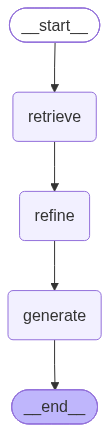

In [14]:
g = StateGraph(State)
g.add_node("retrieve", retrieve)
g.add_node("refine", refine)
g.add_node("generate", generate)

g.add_edge(START, "retrieve")
g.add_edge("retrieve", "refine")
g.add_edge("refine", "generate")
g.add_edge("generate", END)

app = g.compile()

app

In [15]:
res = app.invoke({
    "question": "Explain the bias–variance tradeoff",
    "docs": [],
    "strips": [],
    "kept_strips": [],
    "refined_context": "",
    "answer": ""
})
print(res["answer"])

The bias–variance tradeoff is a key concept in machine learning that describes how a model's generalization error can be broken down into three components: 

- **Bias**: This error arises from incorrect assumptions in the learning algorithm, such as assuming a linear relationship when the true relationship is quadratic. A high-bias model tends to underfit the training data.

- **Variance**: This error is caused by the model's excessive sensitivity to small fluctuations in the training data. 

Balancing bias and variance is crucial for achieving optimal model performance.


In [16]:
print(res['docs'][0].page_content)
print('*'*100)
print(res['docs'][1].page_content)
print('*'*100)
print(res['docs'][2].page_content)
print('*'*100)
print(res['docs'][3].page_content)

10 This notion of bias is not to be confused with the bias term of linear models.
Figure 4-16. Learning curves for the polynomial model
One way to improve an overfitting model is to feed it more training
da
ta until the validation error reaches the training error.
The Bias/Variance Tradeoff
An importan
t theoretical result of statistics and Machine Learning is the fact that a
model’s generaliza
tion error can be expressed as the sum of three very different
errors:
Bias
This part of the generalization error is due to wrong assumptions, such as assum‐
ing that the data is linear when it is actually quadratic. A high-bias model is most
likely to underfit the training data.10
Variance
This part is due to the model’s excessive sensitivity to small variations in the
training data. A model with many degrees of freedom (such as a high-degree pol‐
****************************************************************************************************
In short, they showed that with this activation 

In [17]:
print(res['refined_context'])

The Bias/Variance Tradeoff An importan t theoretical result of statistics and Machine Learning is the fact that a model’s generaliza tion error can be expressed as the sum of three very different errors: Bias This part of the generalization error is due to wrong assumptions, such as assum‐ ing that the data is linear when it is actually quadratic.
A high-bias model is most likely to underfit the training data.10 Variance This part is due to the model’s excessive sensitivity to small variations in the training data.
